In [8]:
import numpy as np
import matplotlib.pyplot as plt
from keras_tuner import GridSearch

In [9]:
yipeng3_x = np.load('../../output/data_yipeng3/lstm-ae/yipeng3_x.npy', allow_pickle=True)
yipeng3_y = np.load('../../output/data_yipeng3/lstm-ae/yipeng3_y.npy', allow_pickle=True)

yipeng3_y = yipeng3_y.reshape((-1, 5, 3))

In [10]:
yipeng3_output_low = np.load('../../output/models/lstm-ae/yipeng3_output_low.npy', allow_pickle=True)
yipeng3_output_high = np.load('../../output/models/lstm-ae/yipeng3_output_high.npy', allow_pickle=True)

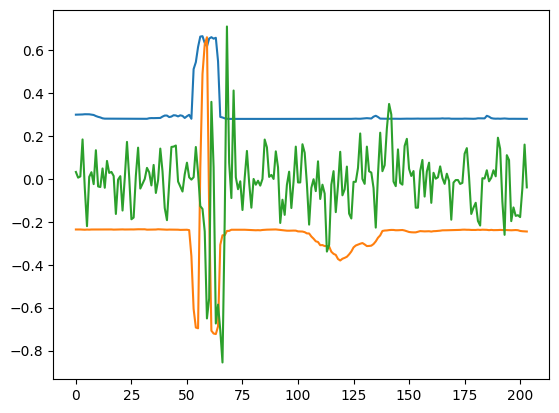

In [11]:
plt.plot(yipeng3_output_high[:, 0, 0])
plt.plot(yipeng3_output_low[:, 0, 0])
plt.plot(yipeng3_y[:, 0, 0])

In [12]:
import sys
sys.path.append('../..')
from src.yipeng3._helper_lstm_ae_functions import (
    lstm_ae,
    lstm_ae_flat,
    lstm_ae_hp
)
import tensorflow as tf
import pickle
from keras.callbacks import EarlyStopping


X_train = np.load('../../output/data_yipeng3/lstm-ae/X_train.npy')
y_train = np.load('../../output/data_yipeng3/lstm-ae/y_train.npy')
X_test = np.load('../../output/data_yipeng3/lstm-ae/X_test.npy')
y_test = np.load('../../output/data_yipeng3/lstm-ae/y_test.npy')
X_val = np.load('../../output/data_yipeng3/lstm-ae/X_val.npy')
y_val = np.load('../../output/data_yipeng3/lstm-ae/y_val.npy')

train_dataset = tf.data\
    .Dataset\
    .from_tensor_slices(
        (X_train, y_train)
    )\
    .batch(64)\
    .shuffle(buffer_size=10_000)

val_dataset = tf.data\
    .Dataset\
    .from_tensor_slices(
        (X_val, y_val)
    )\
    .batch(64)\
    .shuffle(buffer_size=10_000)

In [13]:
tf.random.set_seed(42)

In [14]:
gs_low = GridSearch(
    hypermodel = lambda hp: lstm_ae_hp(
        tau=0.025,
        hp=hp,
        n_out_features=y_train.shape[2],
        n_out_timesteps=y_train.shape[1]
    ),
    objective = 'val_loss',
    directory='../../output/models/lstm-ae-yipeng3-08-16-1',
    project_name='lstm-ae-low'
)

print(gs_low.get_best_hyperparameters()[0].values)

model_low = lstm_ae(
    tau=0.025,
    n_out_features=3,
    n_out_timesteps=5,
    **gs_low.get_best_hyperparameters()[0].values
)

history_low = model_low.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=200,
    callbacks=EarlyStopping(patience=20)
)

Reloading Tuner from ../../output/models/lstm-ae-yipeng3-08-16-1/lstm-ae-low/tuner0.json
{'latent_dim': 5, 'drop_frac': 0.25, 'l1': 0.01}
Epoch 1/200
14278/14278 [==============================] - 52s 3ms/step - loss: 0.0091 - val_loss: 0.0079
Epoch 2/200
11384/14278 [======================>.......] - ETA: 8s - loss: 0.0080

KeyboardInterrupt: 

In [ ]:
gs_high = GridSearch(
    hypermodel = lambda hp: lstm_ae_hp(
        tau=0.975,
        hp=hp,
        n_out_features=y_train.shape[2],
        n_out_timesteps=y_train.shape[1]
    ),
    objective = 'val_loss',
    directory='../../output/models/lstm-ae-yipeng3-08-16-1',
    project_name='lstm-ae-low'
)

model_high = lstm_ae(
    tau=0.975,
    n_out_features=3,
    n_out_timesteps=5,
    **gs_high.get_best_hyperparameters()[0].values
)

history_high = model_high.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=200,
    callbacks=EarlyStopping(patience=20)
)

Reloading Tuner from ../../output/models/lstm-ae-yipeng3-08-16-1/lstm-ae-low/tuner0.json
Epoch 1/200
14278/14278 [==============================] - 49s 3ms/step - loss: 0.0088 - val_loss: 0.0079
Epoch 2/200
14278/14278 [==============================] - 47s 3ms/step - loss: 0.0080 - val_loss: 0.0075
Epoch 3/200
14278/14278 [==============================] - 47s 3ms/step - loss: 0.0077 - val_loss: 0.0074
Epoch 4/200
14278/14278 [==============================] - 46s 3ms/step - loss: 0.0076 - val_loss: 0.0076
Epoch 5/200
14278/14278 [==============================] - 47s 3ms/step - loss: 0.0075 - val_loss: 0.0072
Epoch 6/200
14278/14278 [==============================] - 46s 3ms/step - loss: 0.0074 - val_loss: 0.0073
Epoch 7/200
14278/14278 [==============================] - 46s 3ms/step - loss: 0.0074 - val_loss: 0.0072
Epoch 8/200
14278/14278 [==============================] - 46s 3ms/step - loss: 0.0073 - val_loss: 0.0071
Epoch 9/200
14278/14278 [==============================] - 46s 

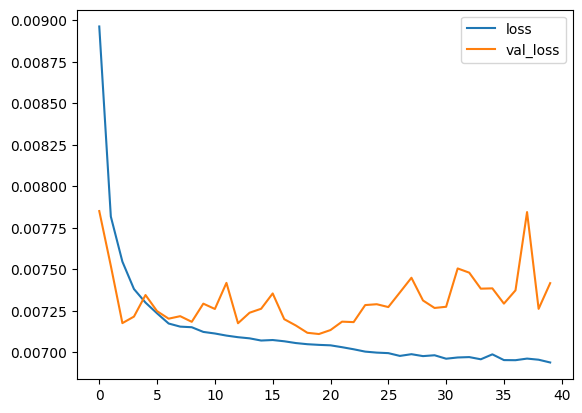

In [ ]:
plt.plot(history_low.history['loss'], label='loss')
plt.plot(history_low.history['val_loss'], label='val_loss')

plt.legend()


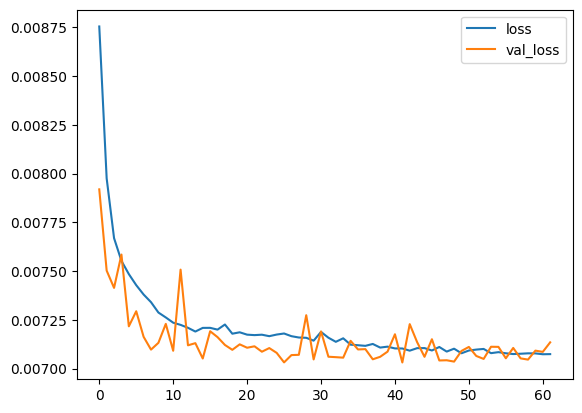

In [ ]:
plt.plot(history_high.history['loss'], label='loss')
plt.plot(history_high.history['val_loss'], label='val_loss')

plt.legend()

In [ ]:
yipeng3_output_high = model_high.predict(yipeng3_x)
yipeng3_output_low = model_low.predict(yipeng3_x)

7/7 [==============================] - 0s 1ms/step


0.9607843137254902

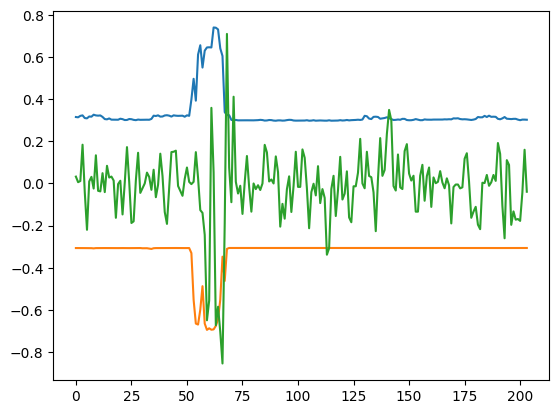

In [ ]:
plt.plot(yipeng3_output_high[:, 0, 0])
plt.plot(yipeng3_output_low[:, 0, 0])
plt.plot(yipeng3_y[:, 0, 0])

np.mean(
    (yipeng3_y[:, :, 0] > yipeng3_output_low[:, :, 0]) &
    (yipeng3_y[:, :, 0] < yipeng3_output_high[:, :, 0])
)

0.953921568627451

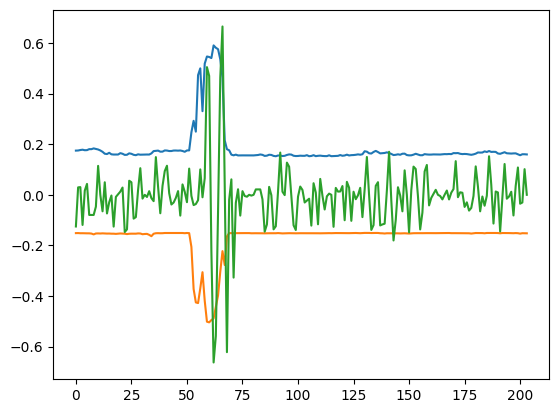

In [ ]:
plt.plot(yipeng3_output_high[:, 0, 1])
plt.plot(yipeng3_output_low[:, 0, 1])
plt.plot(yipeng3_y[:, 0, 1])

np.mean(
    (yipeng3_y[:, :, 1] > yipeng3_output_low[:, :, 1]) &
    (yipeng3_y[:, :, 1] < yipeng3_output_high[:, :, 1])
)

0.9715686274509804

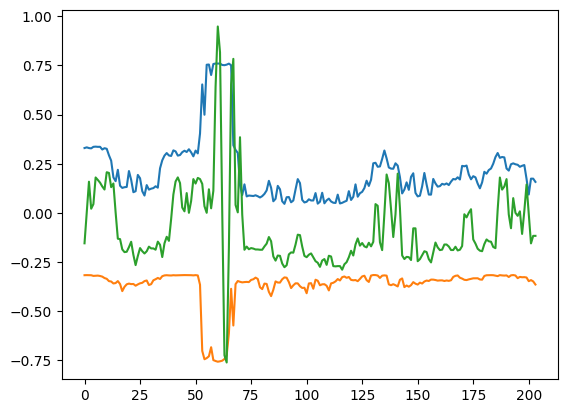

In [ ]:
plt.plot(yipeng3_output_high[:, 0, 2])
plt.plot(yipeng3_output_low[:, 0, 2])
plt.plot(yipeng3_y[:, 0, 2])

np.mean(
    (yipeng3_y[:, :, 2] > yipeng3_output_low[:, :, 2]) &
    (yipeng3_y[:, :, 2] < yipeng3_output_high[:, :, 2])
)

In [ ]:
y_pred = model_low.predict(X_test)

6333/6333 [==============================] - 6s 967us/step


In [ ]:
from sklearn.metrics import mean_pinball_loss

In [ ]:
y_high = model_high.predict(X_test)
y_low = model_low.predict(X_test)

picp_res = np.mean( (y_test < y_high) & (y_test > y_low), axis=0 )
pinaw_res = np.mean( np.abs(y_high - y_low), axis=0 )

loss_low_res = mean_pinball_loss(y_test.reshape((-1, 15)), y_low.reshape((-1,15)), alpha=0.025, multioutput='raw_values')
loss_high_res = mean_pinball_loss(y_test.reshape((-1, 15)), y_high.reshape((-1,15)), alpha=0.975, multioutput='raw_values')

6333/6333 [==============================] - 6s 993us/step


In [ ]:
import traceback

try:
    y_high.dump('../../y_high_lstm_yipeng3.npy')
    y_low.dump('../../y_low_lstm_yipeng3.npy')

except:
    print('failed', traceback.format_exc())

In [ ]:
import pandas as pd

In [ ]:
df_picp = pd.DataFrame(picp_res, columns=['delta_cog', 'delta_dif', 'dif'])
df_picp['time_step'] = list(range(5,30,5))
df_picp

,delta_cog,delta_dif,dif,time_step
0,0.975223,0.975119,0.990900,5
1,0.975218,0.978381,0.991275,10
2,0.975243,0.977858,0.989425,15
3,0.975218,0.977784,0.987027,20
4,0.975198,0.977251,0.984466,25


In [ ]:
df_pinaw = pd.DataFrame(pinaw_res, columns=['delta_cog', 'delta_dif', 'dif'])
df_pinaw['time_step'] = list(range(5,30,5))
df_pinaw

,delta_cog,delta_dif,dif,time_step
0,0.628342,0.331716,0.578783,5
1,0.629326,0.340912,0.607024,10
2,0.629689,0.340420,0.612187,15
3,0.629717,0.340924,0.614366,20
4,0.629730,0.340774,0.615214,25


In [ ]:
df_loss_low = pd.DataFrame(loss_low_res.reshape((5, 3)), columns=['delta_cog', 'delta_dif', 'dif'])
df_loss_low['time_step'] = list(range(5,30,5))
df_loss_low

,delta_cog,delta_dif,dif,time_step
0,0.008697,0.004265,0.008568,5
1,0.008769,0.004455,0.008715,10
2,0.008755,0.004434,0.008786,15
3,0.008761,0.004455,0.008838,20
4,0.008763,0.004467,0.008881,25


In [ ]:
df_loss_high = pd.DataFrame(loss_high_res.reshape((5, 3)), columns=['delta_cog', 'delta_dif', 'dif'])
df_loss_high['time_step'] = list(range(5,30,5))
df_loss_high

,delta_cog,delta_dif,dif,time_step
0,0.008792,0.004680,0.006583,5
1,0.008762,0.004730,0.007122,10
2,0.008782,0.004762,0.007280,15
3,0.008772,0.004777,0.007386,20
4,0.008778,0.004791,0.007481,25


In [23]:
df_picp.to_csv('../../output/data_yipeng3/lstm-ae/picp-lstm.csv')
df_pinaw.to_csv('../../output/data_yipeng3/lstm-ae/pinaw-lstm.csv')

In [24]:
df_picp.to_csv('df_picp_lstm_yipeng.csv')
df_pinaw.to_csv('df_pinaw_lstm_yipeng.csv')

In [25]:
df_picp.to_csv('../../output/data_eagles_vezhen/lstm-ae/picp-lstm.csv')
df_pinaw.to_csv('../../output/data_eagles_vezhen/lstm-ae/pinaw-lstm.csv')
df_loss_low.to_csv('../../output/data_eagles_vezhen/lstm-ae/loss_low-lstm.csv')
df_loss_high.to_csv('../../output/data_eagles_vezhen/lstm-ae/loss_high-lstm.csv')

In [ ]:
y_val_low = model_low.predict(X_val)
y_val_high = model_high.predict(X_val)

val_mmsis = np.load('../../output/data_yipeng3/lstm-ae//val-mmsis.npy', allow_pickle=True)
val_days = np.load('../../output/data_yipeng3/lstm-ae/val-days.npy', allow_pickle=True)

in_pi_mask = (y_val > y_val_low) & (y_val < y_val_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)

thresh_delta_cog = np.quantile(df['delta_cog'], 0.05)
thresh_delta_dif = np.quantile(df['delta_dif'], 0.05)
thresh_dif = np.quantile(df['dif'], 0.05)

print( 'delta_cog limit:', np.quantile(df['delta_cog'], 0.05) )
print( 'delta_dif liimt:', np.quantile(df['delta_dif'], 0.05) )
print( 'dif liimt:', np.quantile(df['dif'], 0.05) )

5809/5809 [==============================] - 5s 876us/step
delta_cog limit: 0.9226298701298699
delta_dif liimt: 0.8728416735028709
dif liimt: 0.922454417952314


In [27]:
in_pi_mask = (y_test > y_low) & (y_test < y_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

test_mmsis = np.load('../../output/data_yipeng3/lstm-ae/test-mmsis.npy', allow_pickle=True)
test_days = np.load('../../output/data_yipeng3/lstm-ae/test-days.npy', allow_pickle=True)

group_results = {}
for ix, (mmsi, day) in enumerate(zip(test_mmsis, test_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)

In [28]:
(df['delta_cog'] < thresh_delta_cog).mean()

0.05360065466448445

In [29]:
(df['dif'] < thresh_dif).mean()

0.029459901800327332

In [30]:
(df['delta_dif'] < thresh_delta_dif).mean()

0.027823240589198037